# 07 Table bodies and figures

Writes the LaTeX table bodies of Tables 5.3, 5.5, 5.10, 5.11 and A1 to A9 (`latex/` in the output folder)
and Figures 5.1 to 5.6 (`figures/`) from the tables produced by notebooks 02 to 05.

In [1]:
import decimal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.common import TABLES, LATEX, FIGURES


def esc(s):
    return str(s).replace("&", "\\&").replace("%", "\\%").replace("$", "\\$")


def fmt(v, nd=2, plus=True):
    """Half-up rounding, so the appendix matches hand-rounded numbers in the text."""
    if pd.isna(v):
        return ""
    d = decimal.Decimal(repr(float(v))).quantize(decimal.Decimal("1." + "0" * nd), rounding=decimal.ROUND_HALF_UP)
    return f"${d:+f}$" if plus else f"${d:f}$"


def star_tex(p):
    """Stars follow the p-value as printed (three decimals)."""
    if pd.isna(p):
        return ""
    p = float(decimal.Decimal(repr(float(p))).quantize(decimal.Decimal("0.001"), rounding=decimal.ROUND_HALF_UP))
    return "^{***}" if p < 0.01 else "^{**}" if p < 0.05 else "^{*}" if p < 0.10 else ""


def sup(p):
    return "$" + star_tex(p) + "$" if star_tex(p) else ""


def write(name, lines):
    (LATEX / name).write_text("\n".join(lines) + "\n")

## CAAR grids

EW columns report the KP-corrected test where the group has one, plain BMP otherwise.

In [2]:
ca = pd.read_csv(TABLES / "caar.csv")
ca["t_EW"] = ca["t_used"].where(ca["t_used"].notna(), ca["t_EW"])
ca["p_EW"] = ca["p_used"].where(ca["p_used"].notna(), ca["p_EW"])


SHOW = {"Firm-hosted ex-INTC": "Firm-hosted ex-Intel", "MA ex-INTC": "MA ex-Intel"}


def grid(groups):
    lines = []
    for g in groups:
        sub = ca[ca["group"] == g]
        lines.append(f"\\multicolumn{{7}}{{l}}{{\\textit{{{esc(SHOW.get(g, g))} ($N={int(sub['N'].max())}$)}}}} \\\\")
        for _, r in sub.iterrows():
            w = r["window"].replace("[", "$[").replace("]", "]$")
            lines.append(f"{w} & {fmt(r['EW_CAAR'])}{sup(r['p_EW'])} & {fmt(r['t_EW'], plus=False)} & "
                         f"{fmt(r['p_EW'], nd=3, plus=False)} & {fmt(r['VW_CAAR'])}{sup(r['p_VW'])} & "
                         f"{fmt(r['t_VW'], plus=False)} & {fmt(r['p_VW'], nd=3, plus=False)} \\\\")
        lines.append("\\addlinespace")
    return lines[:-1]


write("app_caar_grid.tex", grid(["Full sample", "US", "US ex-foreign", "EU", "EU ex-Nokia"]))
write("app_caar_grid_types.tex", grid(["Firm-hosted", "Firm-hosted ex-INTC", "MA", "MA ex-INTC", "CP", "CM",
                                       "CS"]))

## Model comparison, leave-one-out, outliers

In [3]:
def p2(p):
    """p-values as in the Chapter 5 model table: two decimals, three below 0.01."""
    return fmt(p, nd=3 if p < 0.01 else 2, plus=False)


mc = pd.read_csv(TABLES / "model_comparison.csv")
lines = []
for g in ["Full sample", "US", "EU", "MA", "CP"]:
    sub = mc[mc["Group"] == g]
    lines.append(f"\\multicolumn{{6}}{{l}}{{\\textit{{{esc(g)} ($N={int(sub['N'].max())}$)}}}} \\\\")
    for model in ("FF5", "FF3", "MM"):
        r1 = sub[(sub["Model"] == model) & (sub["Window"] == "[-1,+1]")].iloc[0]
        r5 = sub[(sub["Model"] == model) & (sub["Window"] == "[-5,+5]")].iloc[0]
        lines.append(f"{model} & {fmt(r1['EW_CAAR'])} & {p2(r1['p_EW'])}{sup(r1['p_EW'])} & "
                     f"{fmt(r1['VW_CAAR'])} & {fmt(r5['EW_CAAR'])} & "
                     f"{p2(r5['p_EW'])}{sup(r5['p_EW'])} \\\\")
    lines.append("\\addlinespace")
write("app_models_grid.tex", lines[:-1])

loo = pd.read_csv(TABLES / "ma_leave_one_out.csv").sort_values("CAAR")
write("app_ma_loo.tex", [f"{esc(r['dropped'])} & {fmt(r['CAAR'])} & {fmt(r['p_EW'], nd=3, plus=False)} \\\\"
                         for _, r in loo.iterrows()])

NAMES = {"TESLA INC": "Tesla", "MICROCHIP TECHNOLOGY INC": "Microchip Technology", "ACCENTURE PLC IRELAND": "Accenture",
         "NVIDIA CORP": "NVIDIA", "SALESFORCE INC": "Salesforce", "INTERNATIONAL BUSINESS MACHS COR": "IBM",
         "TEXAS INSTRUMENTS INC": "Texas Instruments", "K L A CORP": "KLA", "TWITTER INC": "Twitter",
         "ON SEMICONDUCTOR CORP": "ON Semiconductor", "INTEL CORP": "Intel", "N X P SEMICONDUCTORS N V": "NXP Semiconductors",
         "NOKIA OYJ": "Nokia", "TELEPERFORMANCE": "Teleperformance"}
CODES = {"Other": "ID/SM/TL"}  # the pooled codes of Table 3.2
ol = pd.read_csv(TABLES / "outliers.csv").sort_values("CAR_1", ascending=False)
missing = set(ol["Company"]) - set(NAMES)
assert not missing, f"add display names for {missing}"
write("app_outliers.tex", [
    f"{esc(NAMES[r['Company']])} & {pd.to_datetime(r['Date']).date()} & {r['Region']} & "
    f"{esc(CODES.get(r['Event_Type'], r['Event_Type']))} & {fmt(r['CAR_1'], nd=1)} \\\\"
    for _, r in ol.iterrows()])

## Panel, CAR difference regression, GARCH

In [4]:
label = {}
for k in range(-5, 6):
    s = f"{k:+d}" if k else "0"
    label[f"d_k{k:+d}"] = f"$D_{{t={s}}}$"
    label[f"d_k{k:+d}_EU"] = f"$D_{{t={s}}} \\times \\mathrm{{EU}}$"


def panel_lines(tab):
    return [f"{label.get(r['variable'], esc(r['variable']))} & {fmt(r['coef'] * 100, nd=3)}{sup(r['p'])} & "
            f"{fmt(r['se'] * 100, nd=3, plus=False) if pd.notna(r['se']) else '--'} & "
            f"{fmt(r['t'], plus=False) if pd.notna(r['t']) else '--'} & "
            f"{fmt(r['p'], nd=3, plus=False) if pd.notna(r['p']) else '--'} \\\\" for _, r in tab.iterrows()]


head = ["\\multicolumn{5}{l}{\\textit{Baseline specification: all coefficients}} \\\\"]
head += panel_lines(pd.read_csv(TABLES / "panel_static.csv"))
head += ["\\addlinespace", "\\multicolumn{5}{l}{\\textit{Fully interacted specification: all coefficients}} \\\\"]
write("app_panel.tex", head + panel_lines(pd.read_csv(TABLES / "panel_dynamic.csv")))
write("app_panel_ref5.tex", panel_lines(pd.read_csv(TABLES / "panel_dynamic_ref5.csv")))

cd = pd.read_csv(TABLES / "car_diff_regression.csv").set_index(["variable", "window"])
names = {"const": "Constant", "EU": "$\\mathrm{EU}$", "logcap": "$\\log(\\mathit{MktCap})$"}
lines = []
for pair in [("[-1,+1]", "[0,+3]"), ("[-3,+3]", "[-5,+5]")]:
    if lines:
        lines.append("\\midrule")
    lines.append(" & " + " & ".join(f"\\multicolumn{{4}}{{c}}{{{w.replace('[', '$[').replace(']', ']$')}}}"
                                    for w in pair) + " \\\\")
    lines.append("\\cmidrule(lr){2-5} \\cmidrule(lr){6-9}")
    lines.append("Variable" + " & Coef.\\ (pp) & Std.\\ error & $t$ & $p$" * 2 + " \\\\")
    lines.append("\\midrule")
    for v in ["const", "EU", "logcap"]:
        cells = [names[v]]
        for w in pair:
            r = cd.loc[(v, w)]
            cells += [f"{fmt(r['coef'] * 100)}{sup(r['p'])}", fmt(r["se"] * 100, plus=False),
                      fmt(r["t"], plus=False), fmt(r["p"], nd=3, plus=False)]
        lines.append(" & ".join(cells) + " \\\\")
write("app_car_diff.tex", lines)

gz = pd.read_csv(TABLES / "garch_z2.csv")
gs = pd.read_csv(TABLES / "garch_summary.csv")
garch_label = {"A": "$A_{it}$", "A_EU": "$A_{it} \\times \\mathrm{EU}_i$"}
lines = [f"{garch_label.get(r['variable'], esc(r['variable']))} & {fmt(r['coef'], nd=3)}{sup(r['p'])} & {fmt(r['se'], nd=3, plus=False)} & {fmt(r['t'], plus=False)} & "
         f"{fmt(r['p'], nd=3, plus=False)} \\\\" for _, r in gz.iterrows()]
lines.append("\\addlinespace")
for reg, name in [("US", "United States"), ("EU", "Europe")]:
    ss = gs[gs["region"] == reg]
    lines.append(f"\\multicolumn{{5}}{{l}}{{{name}: {len(ss)} firms, median $\\hat{{a}}={ss['alpha'].median():.3f}$, "
                 f"$\\hat{{b}}={ss['beta'].median():.3f}$, persistence ${ss['persistence'].median():.3f}$}} \\\\")
write("app_garch.tex", lines)

## European-minus-US differences: raw, CAR regression, matched pairs

In [5]:
mt = pd.read_csv(TABLES / "matched_us_eu.csv").set_index("window")
lines = []
for w in ["[-1,+1]", "[0,+3]", "[-3,+3]", "[-5,+5]"]:
    eu = ca[(ca["group"] == "EU") & (ca["window"] == w)]["EW_CAAR"].iloc[0]
    us = ca[(ca["group"] == "US") & (ca["window"] == w)]["EW_CAAR"].iloc[0]
    r = cd.loc[("EU", w)]
    lines.append(f"{w.replace('[', '$[').replace(']', ']$')} & {fmt(eu - us)} & {fmt(r['coef'] * 100)}{sup(r['p'])} & "
                 f"{fmt(r['p'], plus=False)} & {fmt(mt.loc[w, 'mean_diff'])}{sup(mt.loc[w, 'p'])} & "
                 f"{fmt(mt.loc[w, 'p'], plus=False)} \\\\")
write("app_matched.tex", lines)

## Firm concentration: firm-level and firm-clustered tests

In [6]:
fl_firm = pd.read_csv(TABLES / "firm_level_caar.csv")
lines = []
for g, name in [("Full sample", "Full sample"), ("US", "US"), ("EU", "Europe")]:
    sub = fl_firm[fl_firm["group"] == g].set_index("window")
    for j, w in enumerate(["[-1,+1]", "[-3,+3]", "[-5,+5]"]):
        r = sub.loc[w]
        lines.append(f"{name if j == 0 else ''} & {w.replace('[', '$[').replace(']', ']$')} & {int(r['N_events'])} & "
                     f"{int(r['N_firms'])} & {fmt(r['firm_mean_CAAR'])}{sup(r['p_firm'])} & "
                     f"{fmt(r['p_firm'], nd=3, plus=False)} & {fmt(r['event_CAAR'])}{sup(r['p_clustered'])} & "
                     f"{fmt(r['p_clustered'], nd=3, plus=False)} \\\\")
    lines.append("\\addlinespace")
write("app_firm_level.tex", lines[:-1])

## Tier magnitude and pre/post-2023 split by Third Bridge status

In [7]:
tm = pd.read_csv(TABLES / "tier_magnitude.csv").set_index("tier")
tiers = [("Firm-hosted", "Firm-hosted"), ("Firm-hosted ex-INTC", "\\quad ex-Intel"),
         ("Conference appearance", "Conference appearance"),
         ("Research-provider or broker session", "Other broker or research session"),
         ("Third Bridge", "Third Bridge call")]
write("app_tier_magnitude.tex", [
    f"{name} & {int(tm.loc[t, 'N'])} & {fmt(tm.loc[t, 'mean_AR0'])} & {fmt(tm.loc[t, 'mean_absAR0'], plus=False)} & "
    + f"{tm.loc[t, 'share_absAR0_gt2']:.0%}".replace("%", "\\%")
    + f" & {fmt(tm.loc[t, 'VR_median'], plus=False)} & {fmt(tm.loc[t, 'mw_p_absAR0_vs_rest'], nd=3, plus=False)} & "
      f"{fmt(tm.loc[t, 'mw_p_VR_vs_rest'], nd=3, plus=False)} \\\\" for t, name in tiers])

po = pd.read_csv(TABLES / "pre_post_2023.csv")
rows = [("US Pre-2023", "Pre-2023, all"), ("US Pre-2023 ex-TB", "\\quad ex-Third Bridge"),
        ("US Pre-2023 TB only", "\\quad Third Bridge only"), ("US Post-2022", "Post-2022, all"),
        ("US Post-2022 ex-TB", "\\quad ex-Third Bridge"), ("US Post-2022 TB only", "\\quad Third Bridge only")]
lines = []
for g, name in rows:
    sub = po[po["group"] == g].set_index("window")
    cells = [name, str(int(sub["N"].max()))]
    for w in ["[-1,+1]", "[0,+3]", "[-3,+3]", "[-5,+5]"]:
        cells += [f"{fmt(sub.loc[w, 'EW_CAAR'])}{sup(sub.loc[w, 'p_used'])}", fmt(sub.loc[w, "p_used"], nd=3, plus=False)]
    lines.append(" & ".join(cells) + " \\\\")
write("app_post2022_tb.tex", lines)
sorted(p.name for p in LATEX.glob("*.tex"))

['app_caar_grid.tex',
 'app_caar_grid_types.tex',
 'app_car_diff.tex',
 'app_firm_level.tex',
 'app_garch.tex',
 'app_ma_loo.tex',
 'app_matched.tex',
 'app_models_grid.tex',
 'app_outliers.tex',
 'app_panel.tex',
 'app_panel_ref5.tex',
 'app_post2022_tb.tex',
 'app_tier_magnitude.tex']

## Figures

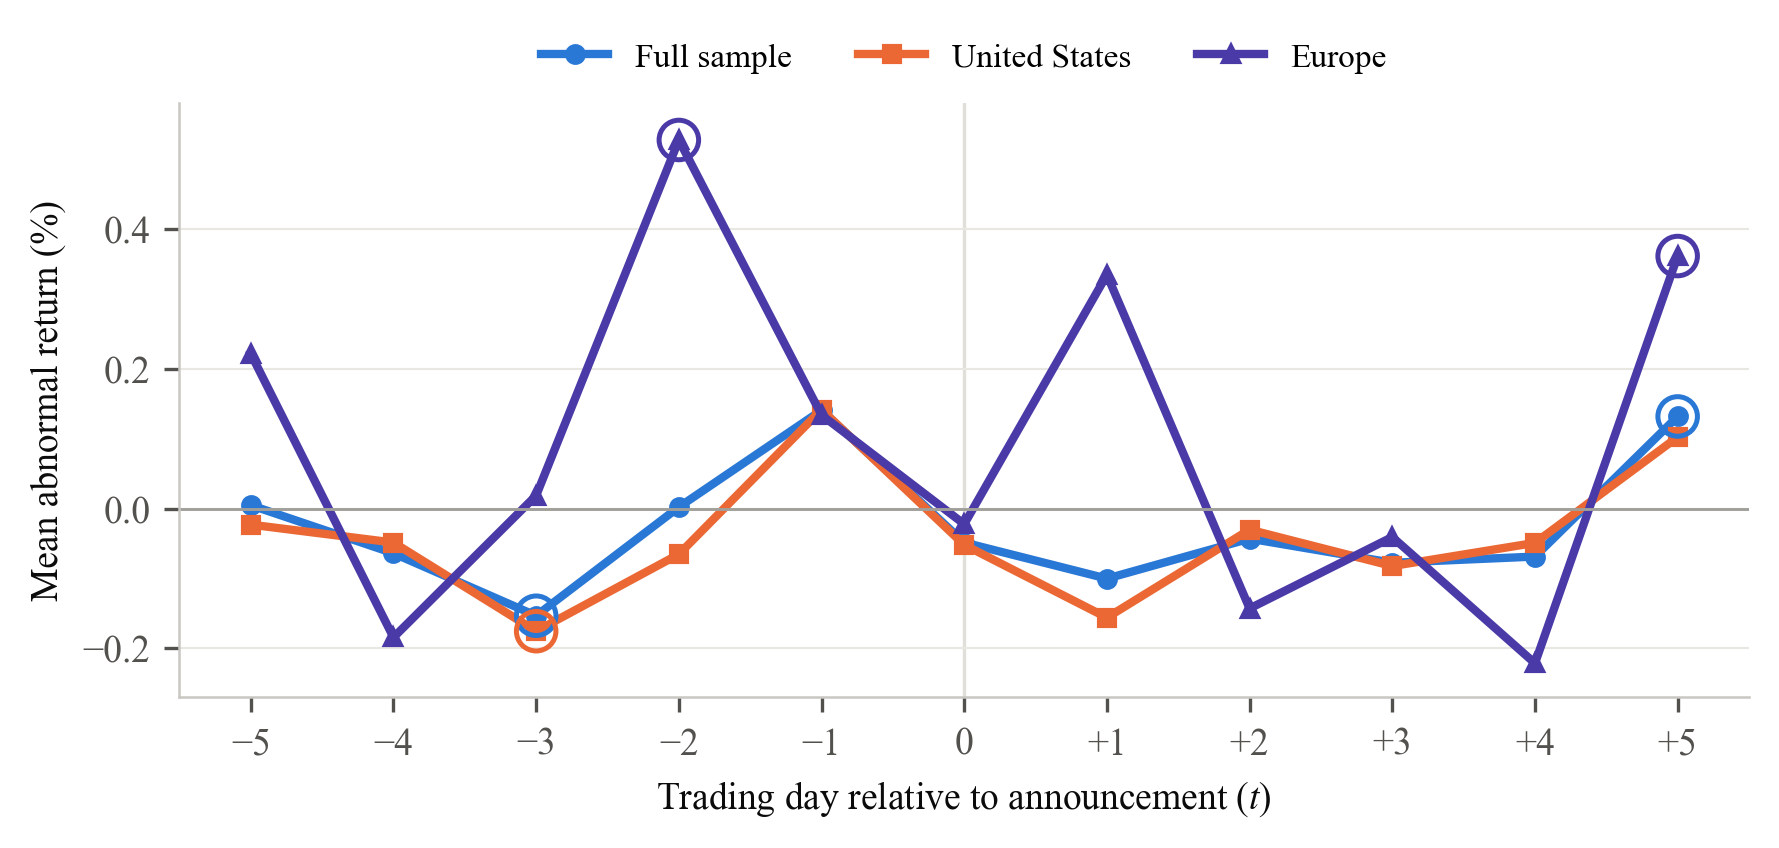

In [8]:
BLUE, ORANGE, VIOLET = "#2a78d6", "#eb6834", "#4a3aa7"
GRAY_TEXT, GRAY_MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
                     "mathtext.fontset": "stix", "font.size": 9, "axes.edgecolor": "#c8c7c2",
                     "axes.linewidth": 0.6, "axes.labelcolor": GRAY_TEXT, "xtick.color": GRAY_MUTED,
                     "ytick.color": GRAY_MUTED, "figure.dpi": 300, "savefig.dpi": 300})


def style(ax, zero="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis=zero, color="#e8e7e2", linewidth=0.5)
    ax.set_axisbelow(True)
    (ax.axhline if zero == "y" else ax.axvline)(0, color="#a09f9a", linewidth=0.7)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.pdf")
    fig.savefig(FIGURES / f"{name}.png", dpi=150)
    plt.show()


# Mean daily abnormal returns; circles mark KP p < 0.05
da = pd.read_csv(TABLES / "daily_ar.csv")
k = np.arange(-5, 6)
fig, ax = plt.subplots(figsize=(6.0, 2.9))
for g, col, mk, lab in [("Full sample", BLUE, "o", "Full sample"), ("US", ORANGE, "s", "United States"),
                        ("EU", VIOLET, "^", "Europe")]:
    sub = da[da["group"] == g].set_index("k").reindex(k)
    ax.plot(k, sub["mean_AR"], color=col, linewidth=2, marker=mk, markersize=4, label=lab)
    sig = sub[sub["p_used"] < 0.05]
    ax.scatter(sig.index, sig["mean_AR"], s=90, facecolors="none", edgecolors=col, linewidths=1.2, zorder=5)
ax.set_xticks(k)
ax.set_xticklabels([f"{x:+d}".replace("-", "\u2212") if x else "0" for x in k])
ax.set_xlabel("Trading day relative to announcement ($t$)")
ax.set_ylabel("Mean abnormal return (%)")
style(ax)
ax.axvline(0, color="#e0dfda", linewidth=0.8, zorder=0)
ax.set_ylim(-0.27, 0.58)
ax.legend(frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, handlelength=2.0)
save(fig, "fig_daily_ar")

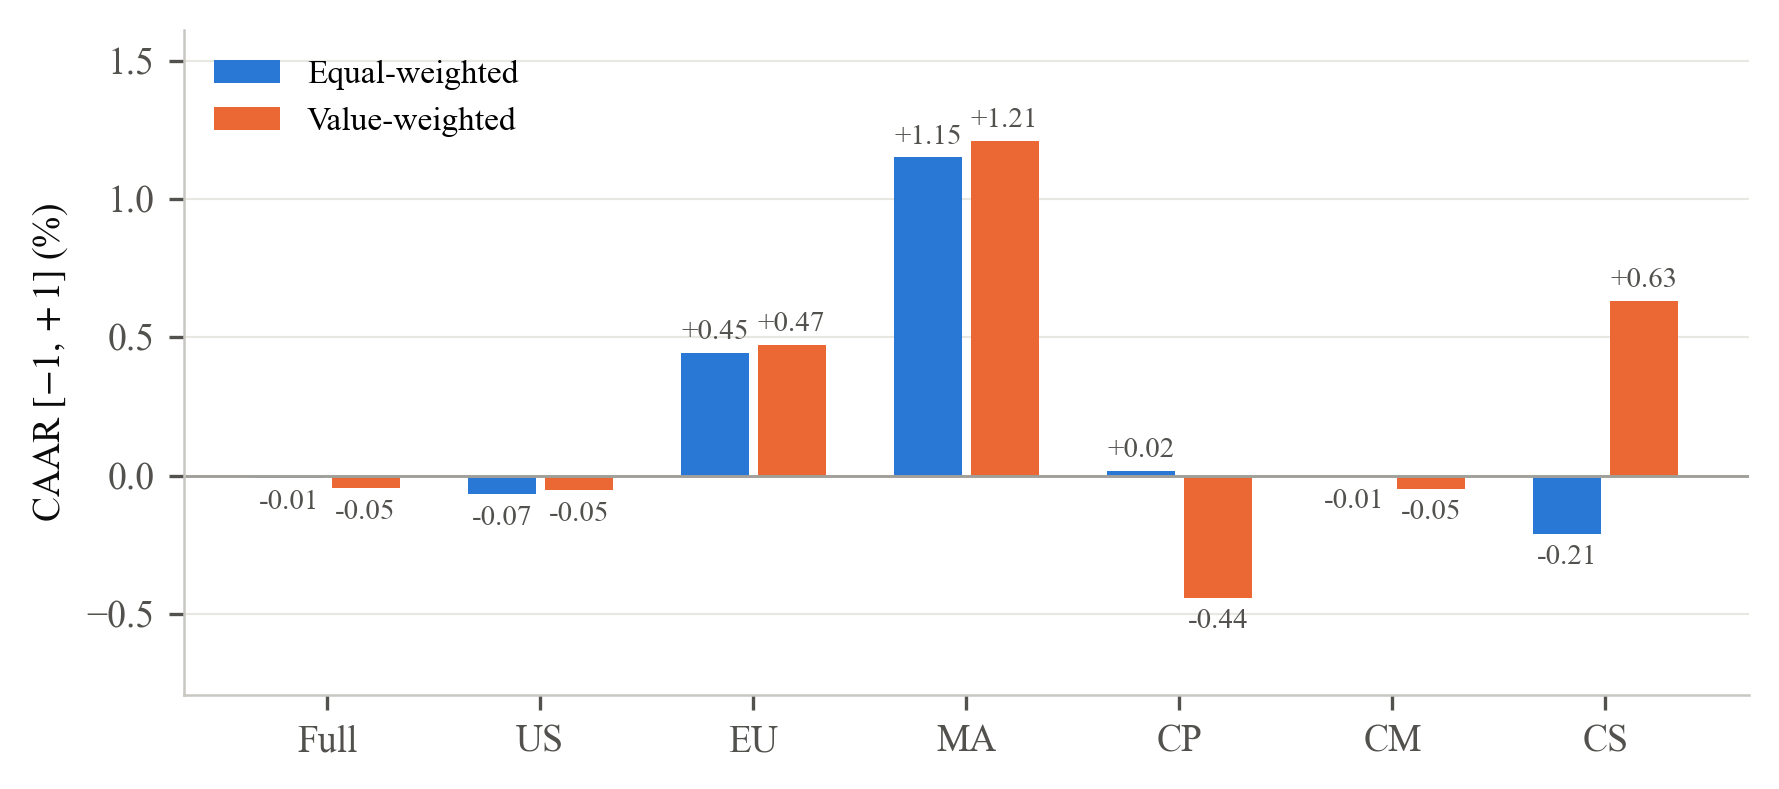

In [9]:
# CAAR[-1,+1] by group, equal- and value-weighted
order = ["Full sample", "US", "EU", "MA", "CP", "CM", "CS"]
row = {g: ca[(ca["group"] == g) & (ca["window"] == "[-1,+1]")].iloc[0] for g in order}
ew, vw = [row[g]["EW_CAAR"] for g in order], [row[g]["VW_CAAR"] for g in order]
x, w = np.arange(len(order)), 0.36
fig, ax = plt.subplots(figsize=(6.0, 2.7))
ax.bar(x - w / 2, ew, width=w - 0.04, color=BLUE, label="Equal-weighted")
ax.bar(x + w / 2, vw, width=w - 0.04, color=ORANGE, label="Value-weighted")
for xs, vals in [(x - w / 2, ew), (x + w / 2, vw)]:
    for xi, v in zip(xs, vals):
        ax.text(xi, v + (0.05 if v >= 0 else -0.11), f"{v:+.2f}", ha="center", fontsize=7, color=GRAY_MUTED)
ax.set_xticks(x, ["Full", "US", "EU", "MA", "CP", "CM", "CS"])
ax.set_ylabel("CAAR $[-1,+1]$ (%)")
ax.set_ylim(min(vw + ew) - 0.35, max(vw + ew) + 0.4)
style(ax)
ax.legend(frameon=False, fontsize=8, loc="upper left")
save(fig, "fig_caar_types")

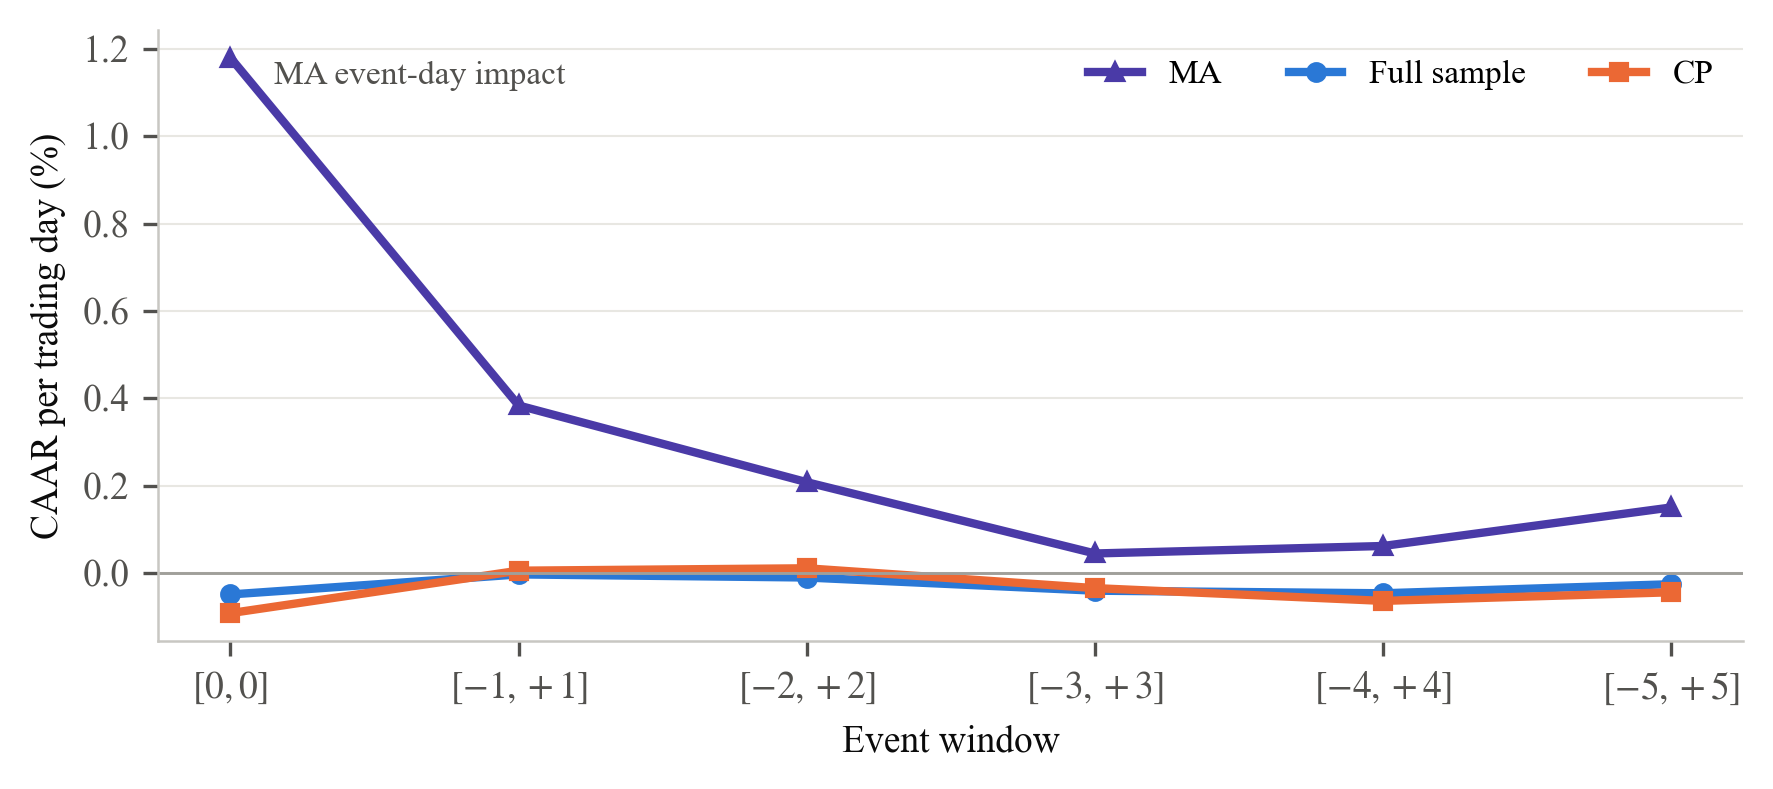

In [10]:
# CAAR per trading day for nested windows
fl = pd.read_csv(TABLES / "flattening.csv")
widths = np.arange(0, 6)
fig, ax = plt.subplots(figsize=(6.0, 2.7))
for g, col, mk in [("MA", VIOLET, "^"), ("Full sample", BLUE, "o"), ("CP", ORANGE, "s")]:
    sub = fl[fl["Group"] == g].set_index("half_width").reindex(widths)
    ax.plot(widths, sub["per_day"], color=col, linewidth=2, marker=mk, markersize=4, label=g)
ma0 = fl[(fl["Group"] == "MA") & (fl["half_width"] == 0)]["per_day"].iloc[0]
ax.text(0.15, ma0 - 0.06, "MA event-day impact", fontsize=8, color=GRAY_MUTED)
ax.set_xticks(widths, ["$[0,0]$", "$[-1,+1]$", "$[-2,+2]$", "$[-3,+3]$", "$[-4,+4]$", "$[-5,+5]$"])
ax.set_xlabel("Event window")
ax.set_ylabel("CAAR per trading day (%)")
style(ax)
ax.legend(frameon=False, fontsize=8, loc="upper right", ncol=3, handlelength=1.6)
save(fig, "fig_flattening")

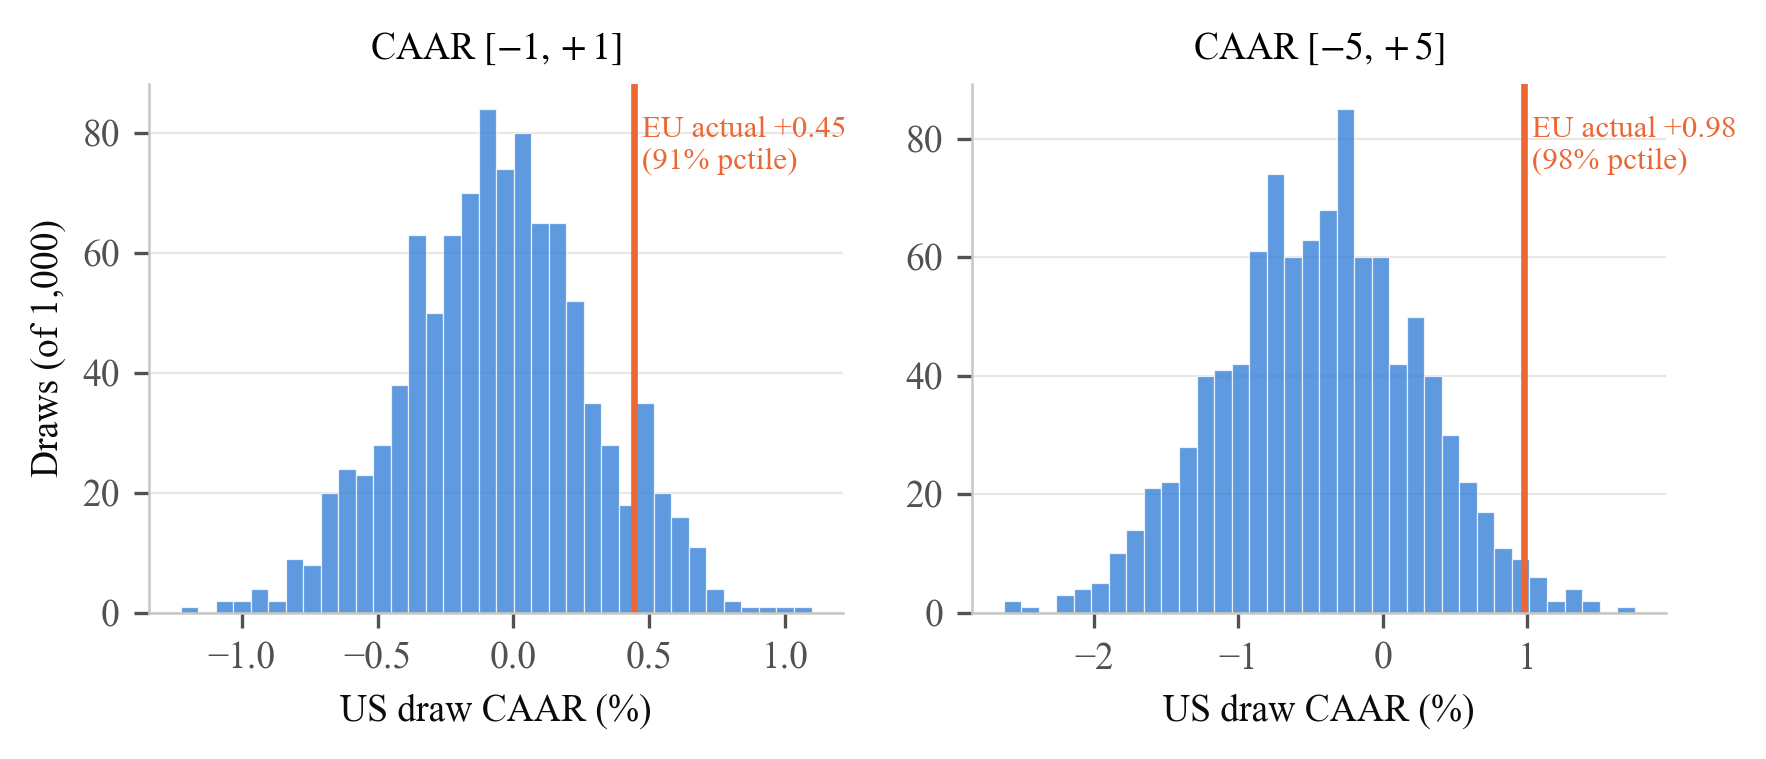

In [11]:
def histogram_pair(draws, summary, panels, xlabel, ylabel, name):
    fig, axes = plt.subplots(1, 2, figsize=(6.0, 2.6))
    for ax, (col, title, actual, pct, text) in zip(axes, panels):
        ax.hist(draws[col], bins=36, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.3)
        ax.axvline(actual, color=ORANGE, linewidth=1.6)
        ax.text(actual, ax.get_ylim()[1] * 0.94, f" {text} {actual:+.2f}\n ({pct:.0%} pctile)", fontsize=7.5,
                color=ORANGE, va="top")
        ax.set_title(title, fontsize=9)
        ax.set_xlabel(xlabel)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#e8e7e2", linewidth=0.5)
        ax.set_axisbelow(True)
    axes[0].set_ylabel(ylabel)
    save(fig, name)


# EU CAAR against 1,000 EU-sized draws from the US sample
ss = pd.read_csv(TABLES / "subsampling.csv").set_index("Window")
histogram_pair(pd.read_csv(TABLES / "subsampling_draws.csv"), ss,
               [(c, f"CAAR ${w}$", ss.loc[w, "EU_actual_CAAR"], ss.loc[w, "percentile_of_actual"], "EU actual")
                for c, w in [("caar_1", "[-1,+1]"), ("caar_5", "[-5,+5]")]],
               "US draw CAAR (%)", f"Draws (of {int(ss['N_draws'].iloc[0]):,})", "fig_subsampling")

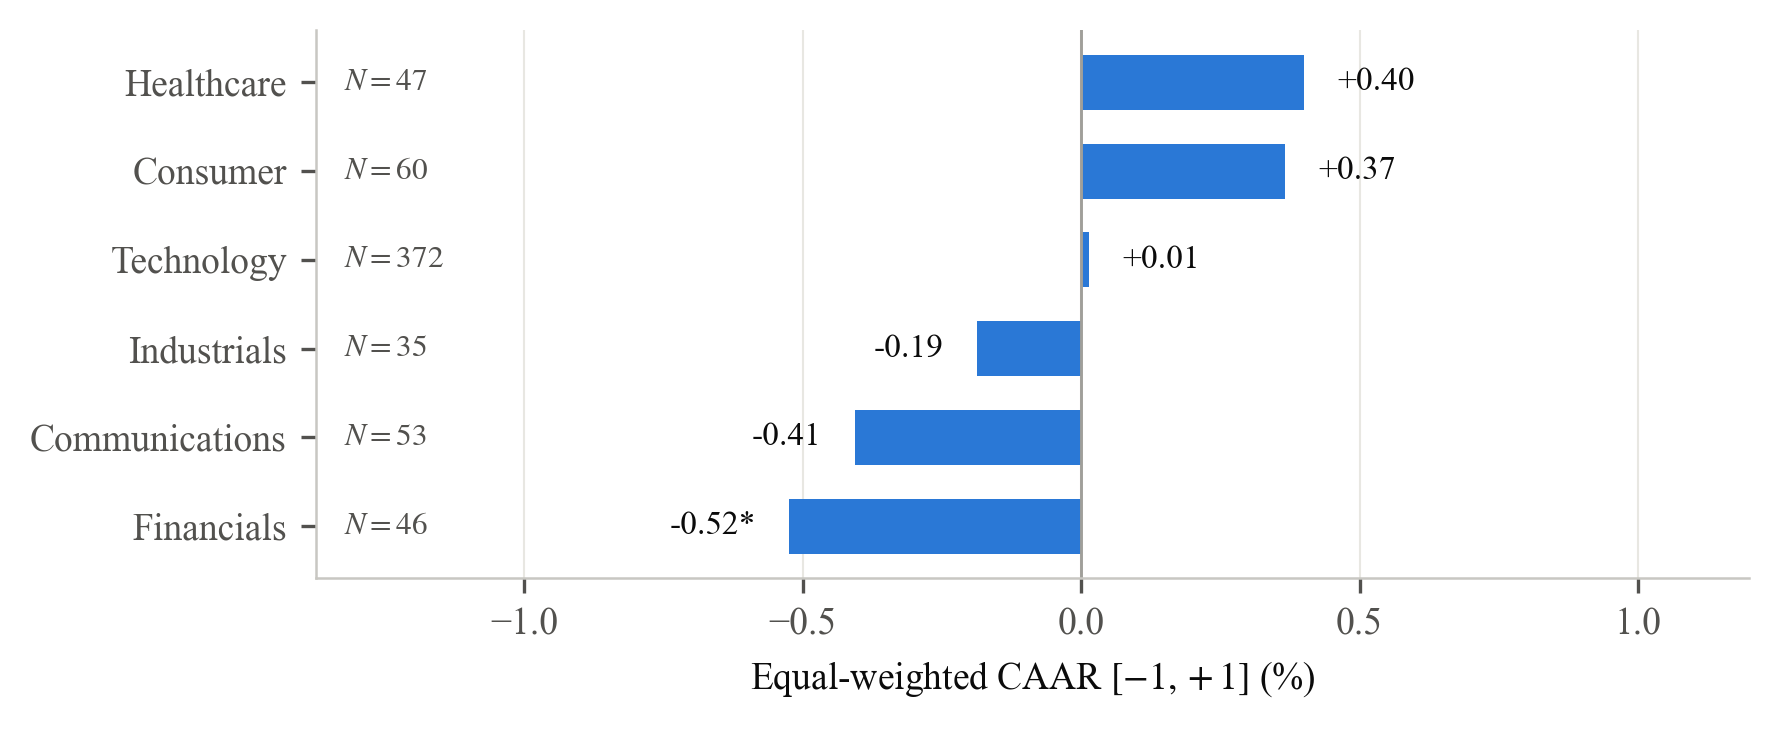

In [12]:
# Sector CAAR[-1,+1]
se = pd.read_csv(TABLES / "sector.csv")
se = se[se["Window"] == "[-1,+1]"].sort_values("EW_CAAR")
fig, ax = plt.subplots(figsize=(6.0, 2.5))
ax.barh(np.arange(len(se)), se["EW_CAAR"], height=0.62, color=BLUE)
xmin = se["EW_CAAR"].min() - 0.85
for i, (_, r) in enumerate(se.iterrows()):
    v = r["EW_CAAR"]
    ax.text(v + (0.06 if v >= 0 else -0.06), i, f"{v:+.2f}{r['sig_used'] if isinstance(r['sig_used'], str) else ''}",
            va="center", ha="left" if v >= 0 else "right", fontsize=8, color=GRAY_TEXT)
    ax.text(xmin + 0.05, i, f"$N{{=}}{int(r['N'])}$", va="center", ha="left", fontsize=7.5, color=GRAY_MUTED)
ax.set_yticks(np.arange(len(se)), se["Sector"])
ax.set_xlabel("Equal-weighted CAAR $[-1,+1]$ (%)")
ax.set_xlim(xmin, se["EW_CAAR"].max() + 0.8)
style(ax, zero="x")
save(fig, "fig_sector")

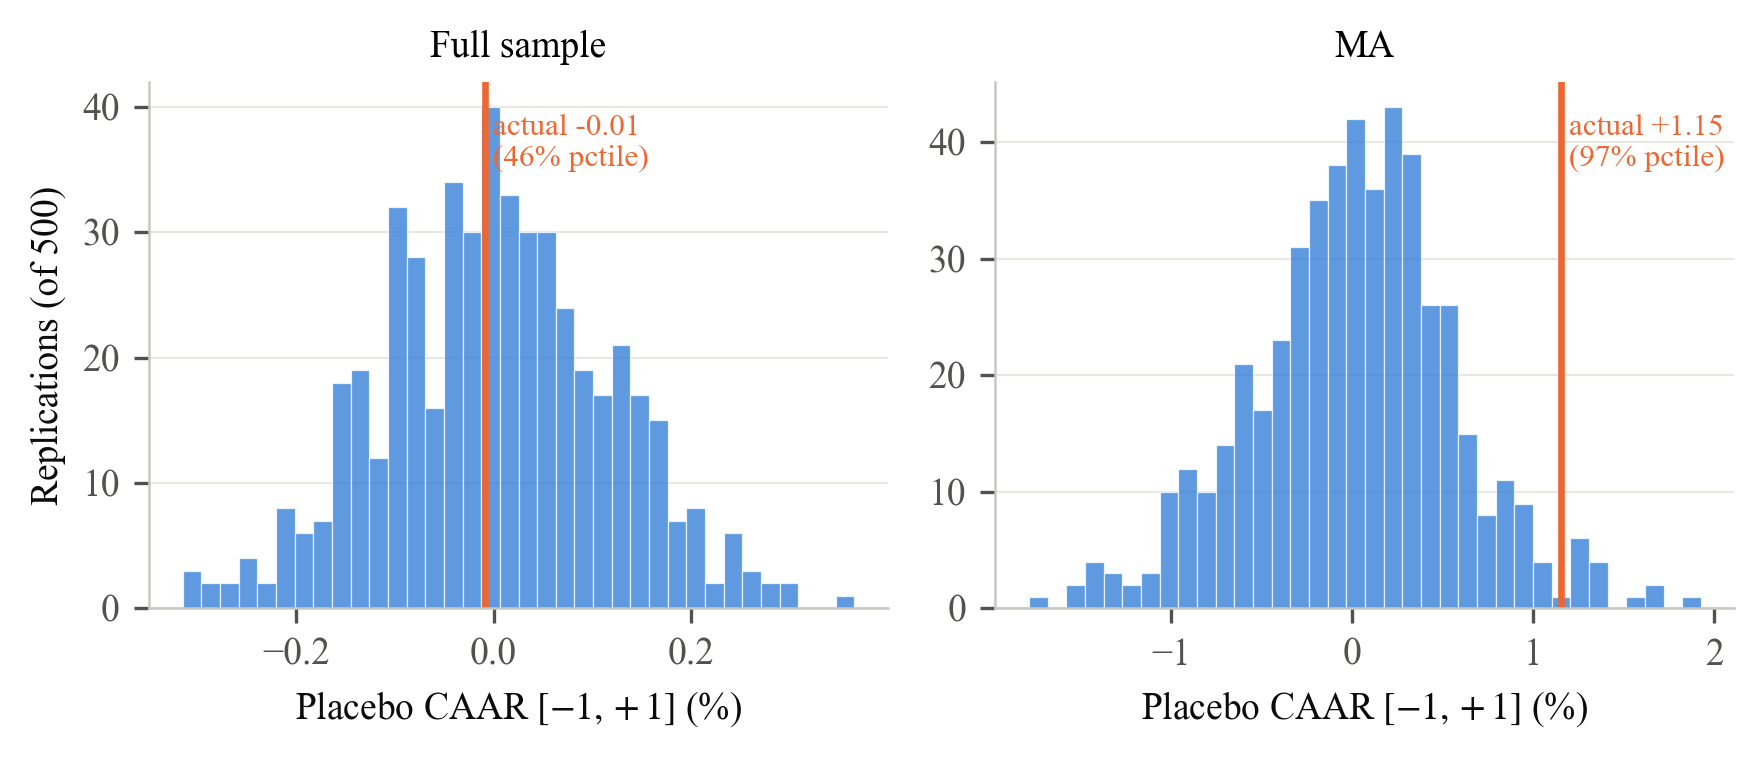

In [13]:
# Placebo distributions of CAAR[-1,+1]
ps = pd.read_csv(TABLES / "placebo.csv").set_index("group")
histogram_pair(pd.read_csv(TABLES / "placebo_draws.csv"), ps,
               [(c, g, ps.loc[g, "actual_CAAR"], ps.loc[g, "percentile_of_actual"], "actual")
                for c, g in [("caar_full", "Full sample"), ("caar_ma", "MA")]],
               "Placebo CAAR $[-1,+1]$ (%)", "Replications (of 500)", "fig_placebo")